### Simulation for ToO strategy
We want to test the performance of the RubiCube ToO follow-up analysis. 
For rubicube we will test for spatial and temporal coincidence, as well as the expected number of neutrinos from a source. We will compute an association probability of:<br>
$$
p(\xi_j|\nu_i,k) = S_{spatial} \times S_{temp} \times S_{emission}. 
$$
By assuming the source belongs to a source type $k$, and then marginalizing over all posible source classes using the classifier's probability:
$$
p(\xi_j|\nu_i) = \sum_k^{N_k}p(\xi_j|\nu_i,k) \cdot p(k|\xi_j)
$$
Where the spatial coincidence comes directly from the healpix map $\omega_i$, the temporal coincidence is computed as a boolean function of:
$$
p(\xi_j|t_\nu) = \begin{cases}
1 & \text{if} t_\nu \in [t_{j,0}, t_{j,0} + \Delta t_k] \\
0 & \text{otherwise}
\end{cases}
$$

For the emission probability, we can obtain the expected number of neutrinos detected for a transient of type k as:
$$
\hat n_k = \frac{L_k\cdot \Delta t_k}{4\pi d_j^2}\cdot A_{eff}(\delta, E_i)
$$
One idea to get ths value normalized is to assume a poission normalized value of:
$$
p_{emission} = \frac{Poiss(\hat n_k, \lambda=1)}{\int Poiss(n_k, \lambda=1)d n_k}
$$


Note: the neutrino energy is not in the map_header, so this needs to be caught and passed from the json alert.

In [67]:
import sys
import os

import numpy as np
import matplotlib.pyplot as plt
import scipy
import astropy.units as u
from astropy.time import Time
import astropy.cosmology as acosmo
import pandas as pd
from scipy.interpolate import interp1d

sys.path.insert(1, '../')
from transient_rates import R_CC, R_TDE, R_sGRB_gaus, plot_rates
from params import p_cosmology
from ic_visualization_clean import read_map, plot_map, evaluate_map, get_map_area


from hop import Stream
from hop.io import StartPosition

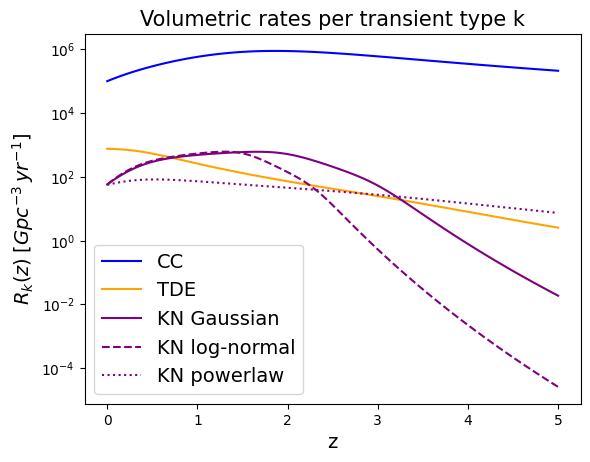

In [2]:
# z_range = np.linspace(0.1, 5, 1000)
R0 = p_cosmology['R0']
for key in R0.keys():
    R0[key] = R0[key].to(u.Gpc ** -3 * u.yr ** -1)

# f = plt.figure(figsize=(8,6))
# plt.plot(z_range, R_CC(z_range, R0['SN CC']), label='Madau')
# # plt.plot(z_range, R_CC(z_range, R0['SN CC'], approx=True), label='Madau approx')
# plt.yscale('log')
# plt.ylabel(r'R(z) [$\text{Mpc}^{-3}\,\text{yr}^{-1}$]', fontsize=14)
# plt.xlabel('z', fontsize=14)
# plt.title("Star formation rate evolution approximation from Madau")
# plt.legend()
# plt.show()
plot_rates('Gpc')

In [3]:
N_sn =  int(1e6)
N_bins = 1000
z_grid = np.linspace(0.1, 5, N_bins)
rates_CC = R_CC(z_grid, R0['SN CC'])
rates_TDE = R_TDE(z_grid, R0['TDE'])
rates_KN = R_sGRB_gaus(z_grid, R0['KN'])

p_CC = rates_CC / np.sum(rates_CC)
p_TDE = rates_TDE / np.sum(rates_TDE)
p_KN = rates_KN / np.sum(rates_KN)


#get N per transient following their local rate ratio
total_r0 = R0['SN CC'] + R0['TDE'] + R0['KN']
N_cc = int(N_sn * R0['SN CC'] / total_r0)
N_tde = int(N_sn * R0['TDE'] / total_r0)
N_kn = int(N_sn * R0['KN'] / total_r0)


CC_sample_z = np.random.choice(z_grid, p=p_CC, size=(N_cc))
TDE_sample_z = np.random.choice(z_grid, p=p_TDE, size=(N_tde))
KN_sample_z = np.random.choice(z_grid, p=p_KN, size=(N_kn))

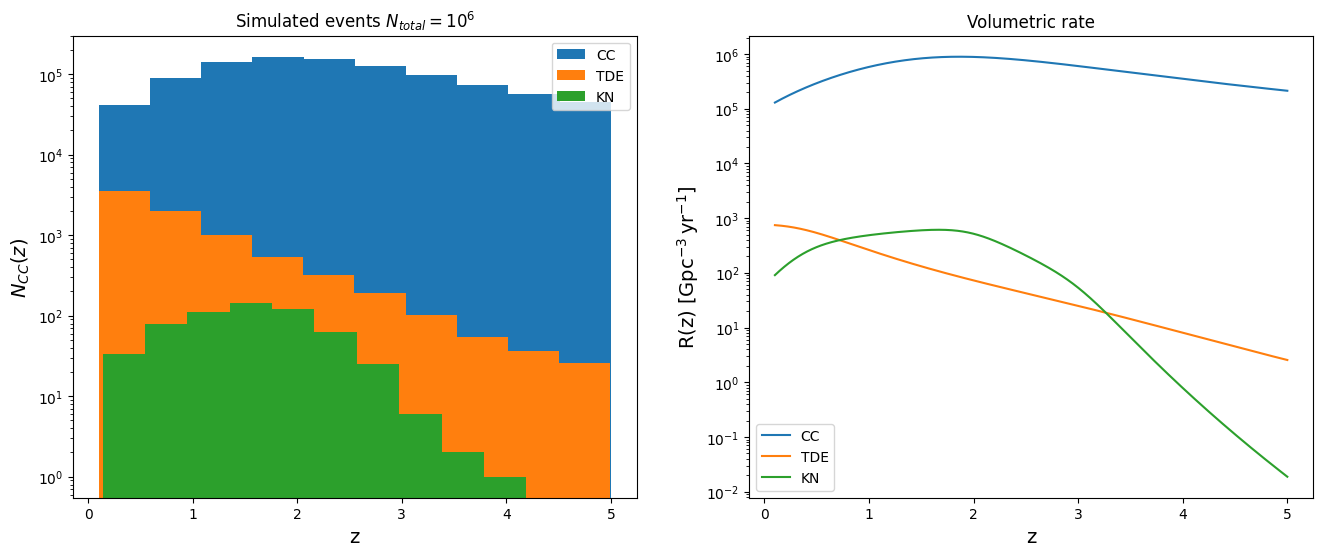

In [4]:

fig, ax = plt.subplots(1, 2, figsize=(16,6))
ax[0].hist(CC_sample_z, label='CC')
ax[0].hist(TDE_sample_z, label='TDE')
ax[0].hist(KN_sample_z, label='KN')
ax[0].set_yscale('log')
ax[0].set_ylabel(r'$N_{CC}(z)$ ', fontsize=14)
ax[0].set_xlabel('z', fontsize=14)
ax[0].set_title(r"Simulated events $N_{total}=10^6$")
ax[0].legend()


z_range = np.linspace(0.1, 5, 1000)

ax[1].plot(z_range, R_CC(z_range, R0['SN CC']), label='CC')
ax[1].plot(z_range, R_TDE(z_range, R0['TDE']), label='TDE')
ax[1].plot(z_range, R_sGRB_gaus(z_range, R0['KN']), label='KN')
ax[1].set_yscale('log')
ax[1].set_ylabel(r'$N_{SN\,CC}(z)$ ', fontsize=14)
ax[1].set_ylabel(r'R(z) [$\text{Gpc}^{-3}\,\text{yr}^{-1}$]', fontsize=14)
ax[1].set_xlabel('z', fontsize=14)
ax[1].set_title("Volumetric rate")
ax[1].legend()

plt.show()

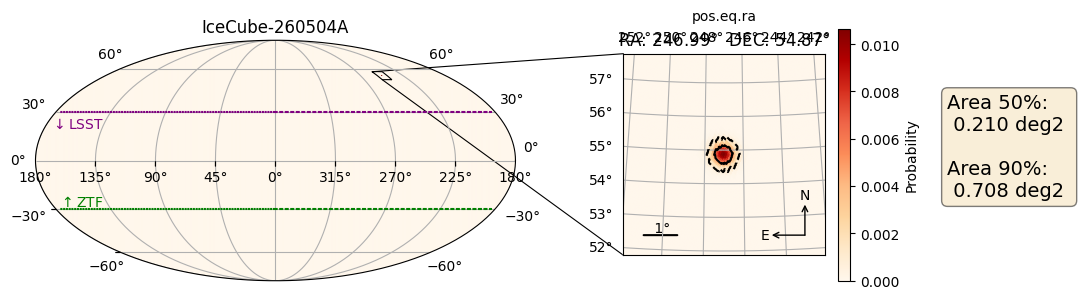

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-260504A.png'

In [5]:
#Latest alert
stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)
alert = alerts[-2]
map_data = read_map(alert['healpix_url'])
plot_map(map_data)

In [75]:
class Transient:
    
    def __init__(self, source_properties, neutrino_properties, transient_times=None, 
                 transient_emissions=None):
        
        self.classification = source_properties['classification'] #keys are formatted as p(k)
        self.z = source_properties['z']
        self.id = source_properties['id']
        self.spatial = np.random.uniform(0.1, 0.5)

        
        self.ra = np.random.uniform(neutrino_properties['ra'] -  neutrino_properties['ra_dec_err']/4,
                                   neutrino_properties['ra'] +  neutrino_properties['ra_dec_err']/4)
        self.ra = np.random.uniform(246.5, 247.5)
                                   #source_properties['ra']
        self.dec = np.random.uniform(neutrino_properties['dec'] -  neutrino_properties['ra_dec_err']/4,
                                   neutrino_properties['dec'] +  neutrino_properties['ra_dec_err']/4) #source_properties['dec']

        #neutrino properties
        self.signalness = neutrino_properties['signalness']
        self.A_90 = neutrino_properties['A_90'] #in deg^2
        self.alert_bkg_rate = neutrino_properties['bkg_rate'] #alerts / day / deg^-2
        self.E= neutrino_properties['E']
        self.m = neutrino_properties['m'] #halpix map

        self.A_eff = self.effective_area(self.E * 1e3, self.dec) #E in GeV, dec in deg

        #transient type properties
        self.transient_times = transient_times #in days
        self.transient_emissions = transient_emissions #number of  emitted neutrinos
    

def effective_area(E_nu, dec):
    '''
    Effective area of the icecube dfetector for a neutrino of reconstructed energy E_nu at a certain declination/

    Params:
    ------
    E_nu: float, in GeV
    '''

    with open('../IC_effective_area/Effa_all_streams_gold_bronze.txt',  'r') as file:
        table  = pd.read_table(file)
    
    if -90 <= dec <= -30:
        area_values = table[' -90- -30 '].values
    elif  -30 <= dec <= -5:
        area_values = table[' -30- -5 '].values
    elif -5 <= dec <= 0:
        area_values = table[' -5-0 '].values
    elif 0 <= dec <= 30:
        area_values = table[' 0-30 '].values
    elif 30 <= dec <= 90:
        area_values = table[' 30-90 '].values

    f = interp1d(table["#E "].values, area_values)
    return f(E_nu) * u.m ** 2

    

   

   

    

   

In [51]:
def random_transient(map_data, name=''):
    '''
    generates random transients within the contour map
    '''

    transient = dict()

    transient['name'] = name

    #properties
    transient['ra'] = np.random.uniform(map_data['header']['ra'] -  map_data['header']['RA_ERR_PLUS_90'],
                            map_data['header']['ra'] +  map_data['header']['RA_ERR_MINUS_90'])
    transient['dec'] = np.random.uniform(map_data['header']['dec'] -  map_data['header']['DEC_ERR_PLUS_90'],
                            map_data['header']['dec'] +  map_data['header']['DEC_ERR_MINUS_90']) 

    t_nu = Time(map_data['header']['DATE-OBS'], format='isot', scale='utc')
    transient['t0'] = np.random.uniform(t_nu.jd - 100, t_nu.jd)

    transient['z'] = np.random.uniform(0, 2)


    #random classification probability
    k_types = ['SNibc','SLSN-I', 'PISN', 'SNII', "SNIA", 'TDE', 'CART', 'SNIa91bg', 'ILOT', 'KN', 'uLens', 'Mdwarf-flare', 'dwarf-nova']
    transient['k'] = {k: np.random.uniform(0, 1000) for k in k_types}
    total = np.sum(list(transient['k'].values()))
    for key in transient['k'].keys():
        transient['k'][key] = transient['k'][key] / total

    
    


             

    
 
    return transient

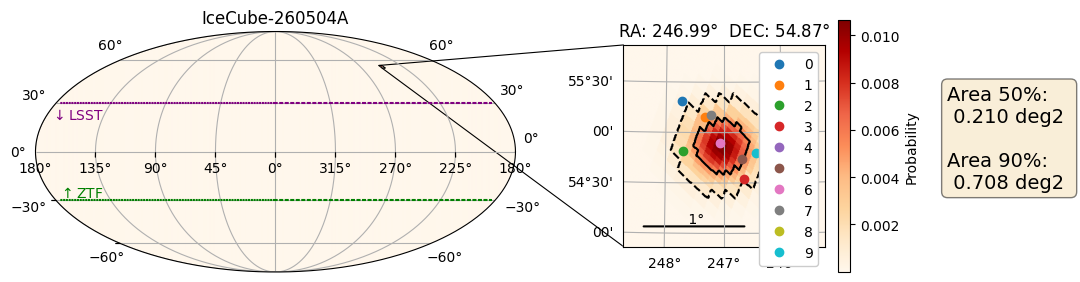

np.float64(0.9999999999999999)

In [52]:
transients = [random_transient(map_data, name=i) for i in range(10)]
plot_map(map_data, plot_source=transients, r=1)
np.sum(list(transients[0]['k'].values()))

In [78]:
transient_times = {
    'SNibc': 20,
    'SNII': 100,
    'TDE': 365,
    'KN': 10,
}
transient_emissions = {
    'SNibc': 5.356980090816673e+31,
    'SNII': 2.678490045408336e+30,
    'TDE': 3.4076010291296514e+33,
    'KN': 6.253210311418056e+34
}

In [79]:
def temp_prob(map_data, transient, transient_times=transient_times):
    t_nu = Time(map_data['header']['DATE-OBS'], format='isot', scale='utc').jd
    p_temp = dict()

    for k in transient_times.keys():
        if transient['t0'] <= t_nu <= transient['t0'] + transient_times[k]:
            p_temp[k] = 1
        else:
            p_temp[k] = 0
    return p_temp

def emission_prob(E_nu, transient, p=p_cosmology):

    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K, 
    
    D_L = cosmo.luminosity_distance(transient['z']).to(u.m)
    A_eff = effective_area(E_nu, transient['dec']) #in m^2

    p_emission = dict()
    for k in transient_emissions.keys():
        L_k = transient_emissions[k]
        p_emission[k] = L_k * transient_times[k] / (4 * np.pi * D_L ** 2) * A_eff
    return p_emission



In [80]:
for transient in transients:
    print(f"p spatial {transient['name']}: ", evaluate_map(map_data['skymap'], ra=transient['ra'], dec=transient['dec']))

p spatial 0:  0.0002981041080099084
p spatial 1:  0.003077909346499508
p spatial 2:  0.0018889921661769471
p spatial 3:  0.002090773995746593
p spatial 4:  0.0006649743939903957
p spatial 5:  0.006120689388825025
p spatial 6:  0.010353387109278045
p spatial 7:  0.003087049259530961
p spatial 8:  0.00026051420116902376
p spatial 9:  0.0033183959432677443


In [81]:
temp_prob(map_data, transients[0])

{'SNibc': 0, 'SNII': 1, 'TDE': 1, 'KN': 0}

In [82]:
E_nu = 1.8 * 1e5 #Gev
emission_prob(E_nu, transients[0])

{'SNibc': <Quantity 1.49923611e-17>,
 'SNII': <Quantity 3.74809027e-18>,
 'TDE': <Quantity 1.74045024e-14>,
 'KN': <Quantity 8.75030198e-15>}

In [83]:
for transient in transients:
    p_spatial = evaluate_map(map_data['skymap'], ra=transient['ra'], dec=transient['dec'])
    p_temp = temp_prob(map_data, transient)
    p_emission = emission_prob(1.8e5, transients[0])

    rubicube = 0

    for k in transient['k']:
        if k not in p_temp.keys():
            continue
        rubicube += p_spatial * p_temp[k] * p_emission[k]
    print(transient['name'], ' RUBICUBE = ', rubicube)

0  RUBICUBE =  5.189470980839434e-18
1  RUBICUBE =  5.358101685328926e-17
2  RUBICUBE =  3.2884048780308864e-17
3  RUBICUBE =  3.6396717411421986e-17
4  RUBICUBE =  1.7404737103774063e-17
5  RUBICUBE =  1.0655049398039013e-16
6  RUBICUBE =  1.8023435609686282e-16
7  RUBICUBE =  5.3740126748690446e-17
8  RUBICUBE =  4.535096467098266e-18
9  RUBICUBE =  5.77674677664988e-17
